# **Introduction**

<div style="text-align: justify;">

***Naive Bayes** is a machine learning classification algorithm based on the Bayes' Theorem that predicts a data point's category based on probability*. It assumes that each feature contributes to the result independently, even if this isn’t always true in reality (this is called the “naive” assumption). Naive Bayes excels in a variety of real-world applications, including spam filtering, document categorisation, and sentiment analysis. This [article](https://www.geeksforgeeks.org/machine-learning/naive-bayes-classifiers/) sums everything up quite nicely. There are **three** types of naive Bayes classifiers, each suited for different types of data:

1. Multinomial Naive Bayes
2. Bernoulli Naive Bayes
3. Gaussian Naive Bayes

</div>

<div style = "text-align: justify;">

## Short Description of the Three Naive Bayes Classifiers

* **Multinomial Naive Bayes:** Multinomial Naive Bayes is a version of the Naive Bayes algorithm that is best suited for discrete data and is commonly used in text classification issues like spam detection or sentiment analysis. Instead of just checking whether a word appears or not (which is the working mechanism of Bernoulli Naive Bayes), it looks at how many times each word repeats in a document and uses those counts to calculate probabilities for each class. For more details, refer to this [article](https://www.geeksforgeeks.org/machine-learning/multinomial-naive-bayes/).

* **Bernoulli Naive Bayes:** Bernoulli Naive Bayes is another category of the Naive Bayes algorithm which is primarily used with binary data and uses the Bernoulli distribution to model feature occurrence. It is used to classify binary features like "yes" or "no", "1" or "0", "true" or "false", and so on. It converts each document into a set of 1s and 0s and learns how likely each word is to appear in different classes. It only considers whether a word or feature is present or absent instead of how often it appears (which is the working mechanism of Multinomial Naive Bayes). This [article](https://www.geeksforgeeks.org/machine-learning/bernoulli-naive-bayes/) digs deep into this.

* **Gaussian Naive Bayes:** Gaussian Naive Bayes is another Naive Bayes algorithm that works with continuous attributes and data features that have a Gaussian (normal) distribution over the dataset. This model was designed for datasets with numerical or continuous features instead of word counts. Gaussian Naive Bayes is commonly used because it works well with small datasets and is simple to build and comprehend. This method works best when features are real-valued and roughly bell-shaped, such as sensor readings or pixel intensities, and is known for being fast and effective even with limited training examples. TF-IDF scores are real-valued too, but they are sparse and heavily skewed, so the Gaussian assumption fits them poorly (we will see the consequence later). This [article](https://www.geeksforgeeks.org/machine-learning/gaussian-naive-bayes/) provides more information.

</div>

<div style="text-align: justify;">

## Aims & Objectives

### **Aim**
To build and rigorously compare three Naive Bayes classifiers (Multinomial, Bernoulli, and Gaussian) for **SMS spam detection**, and to identify which variant most reliably separates spam from legitimate (ham) messages without overfitting or leaking information from the evaluation data.

### **Broad Objective**
To develop and evaluate a machine learning text-classification workflow on the SMS Spam Collection dataset that predicts whether a message is spam or ham, and to determine the most suitable Naive Bayes variant using leakage-safe pipelines and metrics appropriate for an imbalanced dataset.

### **Specific Objectives**
1. To load and explore the SMS Spam Collection dataset (5,572 labelled messages), checking the class distribution to confirm the imbalance between ham and spam messages and to guide a stratified train–test split.
2. To encode the target variable and the raw text appropriately for each model, using `CountVectorizer` (word counts) for Multinomial Naive Bayes, a binary `CountVectorizer` (word presence) for Bernoulli Naive Bayes, and `TfidfVectorizer` (TF-IDF weights) for Gaussian Naive Bayes.
3. To bundle each vectorizer and classifier into a scikit-learn `Pipeline`, defined once and reused throughout the notebook, so that vocabulary and IDF weights are learned only from training data and **preprocessing leakage** is avoided in both the test evaluation and cross-validation.
4. To evaluate and compare the three models on the held-out test set using accuracy, precision, recall, F1 score (spam class), confusion matrices, and ROC-AUC, with particular attention to the trade-off between false positives (legitimate messages flagged as spam) and false negatives (spam that slips through).
5. To assess generalization by comparing training and testing performance (overfitting check) and by running 5-fold cross-validation on both accuracy and spam-class F1, since accuracy alone is misleading on an imbalanced dataset.
6. To visually compare the models across accuracy, F1 score, and ROC-AUC, and to select the best-performing model while explaining why its underlying assumptions suit (or do not suit) text data.

</div>

# **Data Preparation**

## Importing the Required Libraries

In [1]:
# data manipulation
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# data loading (only used if the local file is missing)
import io
import zipfile
import requests

# model selection & validation
from sklearn.model_selection import train_test_split, cross_val_score

# text preprocessing & pipelines
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

# machine learning models
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, GaussianNB

# model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

## Loading the Dataset

<div style="text-align: justify;">

This notebook goes through the three Naive Bayes classifiers (Gaussian, Multinomial, and Bernoulli) using the sklearn library. The dataset used is the **SMS Spam Collection** dataset, which is a set of 5572 SMS tagged messages that have been collected for mobile phone spam research. The dataset is available [here](https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip) if want to download and work manually or [here](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) if want to directly fetch from online. Both versions of the code are tied with a `try-except` block. If the local file is not found, it will fetch from online.

</div>

In [2]:
# trying to load the local file first
try:
    sms = pd.read_csv(
        filepath_or_buffer = "../datasets/SMSSpamCollection",
        sep = "\t",
        header = None,
        names = ["label", "message"]
    )
    print("File loaded successfully from local storage.")

# downloading and loading the dataset from the web if the file is not found
except FileNotFoundError:
    print("Local file not found. Fetching it online...")

    # downloading the zip file from UCI repository
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
    r = requests.get(url)

    # extracting and reading the data file inside the zip
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        with z.open("SMSSpamCollection") as f:
            sms = pd.read_csv(
                filepath_or_buffer = f,
                sep = "\t",
                header = None,
                names = ["label", "message"]
            )

    print("File successfully fetched online and loaded.")

# displaying the first few rows
sms.head(n = 10)

Local file not found. Fetching it online...
File successfully fetched online and loaded.


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


### **Checking the Distribution of the Target Variable**

We quickly check the proportion of hams and spams to check the overall balance. This will later help us in the train-test split.

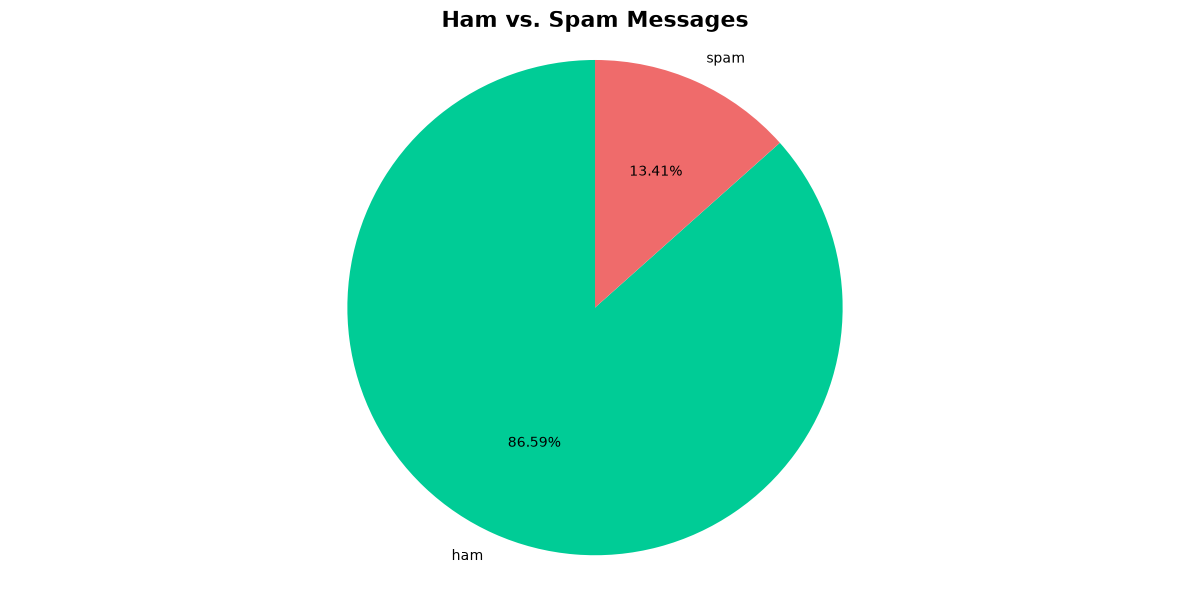

In [3]:
# calculating the ratio of hams and spams
spam_ham_ratio = round(number = sms["label"].value_counts(normalize = True), ndigits = 4) * 100

# creating a simple pie chart
plt.figure(figsize = (12, 6))
plt.pie(
    x = spam_ham_ratio.values,
    labels = spam_ham_ratio.index,
    autopct = "%1.2f%%",
    colors = ["#00CC96", "#EF6B6B"],
    startangle = 90
)

# adding title and formatting the chart
plt.title(label = "Ham vs. Spam Messages", fontsize = 16, fontweight = "bold")
plt.axis("equal")
plt.tight_layout()
plt.show()

So, this dataset has roughly **87%** ham messages and **13%** spam messages. The dataset is imbalanced, which means that the number of instances in each class is not equal. This can lead to biased results if not handled properly. We will preserve this spam:ham ratio while splitting the dataset.

# **Machine Learning**

## Data Preparation

To conduct machine learning, first we need to prepare the data accordingly. 

### **Encoding the Target Variable**

We encode the labels, where `ham` is encoded as 0 and `spam` is encoded as 1.

In [4]:
# encoding the target variable
sms["label_encoding"] = sms["label"].map({"ham": 0, "spam": 1})

### **Conducting a Train-Test Split**

<div style="text-align: justify;">

Now, time for a train-test split. We will use **70%** of the data for training and **30%** for testing. We will also use stratified sampling to ensure that the proportion of ham and spam messages is the same in both the training and testing sets. This matters here because spam is only about 13% of the data, so a plain random split could leave the test set with noticeably fewer (or more) spam messages than the training set.

</div>

In [5]:
# conducting the train-test split
X_train, X_test, y_train, y_test = train_test_split(
    sms["message"],
    sms["label_encoding"],
    test_size = 0.3,
    stratify = sms["label_encoding"],
    random_state = 49
)

### **Text Encoding & Model Pipelines**

<div style="text-align: justify;">

Each model needs the raw text encoded differently, so we pair every classifier with its own vectorizer:

* **Multinomial Naive Bayes** uses `CountVectorizer`, which converts a collection of text documents to a matrix of token counts, i.e., it counts how many times each word appears.
* **Bernoulli Naive Bayes** uses the same encoder but with `binary = True`, which converts the counts to 1 (the word is present) or 0 (it is not).
* **Gaussian Naive Bayes** uses `TfidfVectorizer`, which converts the text to a matrix of TF-IDF features. **TF-IDF** stands for *Term Frequency-Inverse Document Frequency*, and it reflects how important a word is to a document in a collection. Gaussian Naive Bayes only accepts dense arrays, while the vectorizer returns a sparse matrix, so we add a small `to_dense` step in between. (It is a named function and not a `lambda` because named functions can be saved and cloned by scikit-learn without any trouble.)

We also use `stop_words = "english"` in all the vectorizers to remove common English words ("the", "is", "in", "and", etc.) that add noise but little signal.

Instead of vectorizing the text separately before passing it to each model, we combine each vectorizer and classifier into a scikit-learn `Pipeline`. We define the three pipelines once and reuse them for training, prediction, ROC curve analysis, overfitting checks, and cross-validation. More importantly, pipelines prevent preprocessing leakage during cross-validation. Each pipeline learns its vocabulary and, where applicable, IDF weights only from the data used to fit it. For the final model, this means using only the training set. During cross-validation, the vectorizer is fitted separately on the training portion of each fold. Without pipelines, vectorizing the entire training set before cross-validation would allow the validation folds to influence the vocabulary and IDF weights, resulting in **preprocessing leakage**.

</div>

In [6]:
# converting a sparse matrix to a dense array, because GaussianNB does not accept sparse input
def to_dense(X):
    return X.toarray()

# MultinomialNB
mnb_pipeline = Pipeline(
    steps = [
        ("vectoriser", CountVectorizer(stop_words = "english")),
        ("classifier", MultinomialNB())
    ]
)

# BernoulliNB
bnb_pipeline = Pipeline(
    steps = [
        ("vectoriser", CountVectorizer(stop_words = "english", binary = True)),
        ("classifier", BernoulliNB())
    ]
)

# GaussianNB
gnb_pipeline = Pipeline(
    steps = [
        ("vectoriser", TfidfVectorizer(stop_words = "english")),
        ("to_dense", FunctionTransformer(func = to_dense, accept_sparse = True)),
        ("classifier", GaussianNB())
    ]
)

## Modeling

We fit the pipelines on the raw training text (each pipeline vectorizes the text internally, using only the training data) and make predictions on the raw test text. We will check the results in the next couple of cells.

In [7]:
# MultinomialNB
mnb_pipeline.fit(X = X_train, y = y_train)
y_predict_test_mnb = mnb_pipeline.predict(X = X_test)

# BernoulliNB
bnb_pipeline.fit(X = X_train, y = y_train)
y_predict_test_bnb = bnb_pipeline.predict(X = X_test)

# GaussianNB
gnb_pipeline.fit(X = X_train, y = y_train)
y_predict_test_gnb = gnb_pipeline.predict(X = X_test)


## Performance & Evaluation

### **Accuracy Scores & Classification Reports**

Now, we calculate the accuracy scores and the spam-class (class 1) F1 scores of all the models along with their classification reports. Since the data is about 87% ham, accuracy alone flatters every model, so the F1 score of the spam class is the more honest number. We keep these F1 scores in variables so that the final comparison chart can reuse them. Then we print the accuracies and the reports together to get a comprehensive report of all the models' performances.

In [8]:
# calculating the accuracy scores for test datasets of the the three models
accuracy_test_mnb = accuracy_score(y_true = y_test, y_pred = y_predict_test_mnb)
accuracy_test_bnb = accuracy_score(y_true = y_test, y_pred = y_predict_test_bnb)
accuracy_test_gnb = accuracy_score(y_true = y_test, y_pred = y_predict_test_gnb)

# calculating the F1 scores of the spam class (class 1) for test datasets of the three models
f1_test_mnb = f1_score(y_true = y_test, y_pred = y_predict_test_mnb)
f1_test_bnb = f1_score(y_true = y_test, y_pred = y_predict_test_bnb)
f1_test_gnb = f1_score(y_true = y_test, y_pred = y_predict_test_gnb)

# generating the Classification reports for test datasets of the the three models
report_mnb = classification_report(y_true = y_test, y_pred = y_predict_test_mnb)
report_bnb = classification_report(y_true = y_test, y_pred = y_predict_test_bnb)
report_gnb = classification_report(y_true = y_test, y_pred = y_predict_test_gnb)

# printing a comprehensive summary Report of the three models
print(
f"""Model Performance Report
         
Report for Multinomial Naive Bayes
Accuracy Score: {accuracy_test_mnb:.3%}
{report_mnb}

Report for Bernoulli Naive Bayes
Accuracy Score: {accuracy_test_bnb:.3%}
{report_bnb}

Report for Gaussian Naive Bayes
Accuracy Score: {accuracy_test_gnb:.3%}
{report_gnb}"""
)

Model Performance Report

Report for Multinomial Naive Bayes
Accuracy Score: 98.684%
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1448
           1       0.97      0.93      0.95       224

    accuracy                           0.99      1672
   macro avg       0.98      0.96      0.97      1672
weighted avg       0.99      0.99      0.99      1672


Report for Bernoulli Naive Bayes
Accuracy Score: 97.189%
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1448
           1       0.99      0.79      0.88       224

    accuracy                           0.97      1672
   macro avg       0.98      0.90      0.93      1672
weighted avg       0.97      0.97      0.97      1672


Report for Gaussian Naive Bayes
Accuracy Score: 87.739%
              precision    recall  f1-score   support

           0       0.99      0.87      0.92      1448
           1       0.52      0.92    

<div style="text-align: justify;">

**Key Insights:**

* For detecting spam messages (class 1), **Multinomial Naive Bayes** achieved the best balance with precision = 0.97, recall = 0.93, and F1 = 0.95, correctly identifying most spam messages with very few false alarms.

* **Bernoulli Naive Bayes** had slightly higher precision (0.99) but much lower recall (0.79), missing more spam messages.

* **Gaussian Naive Bayes** performed the worst on spam detection, with low precision (0.52) despite good recall (0.92), meaning it incorrectly labeled many ham messages as spam.

</div>

### **Confusion Matrices**

Now, we generate the confusion matrices for all three models and plot them side by side for a quick and easier comparison. We also formatted the graph accordingly.

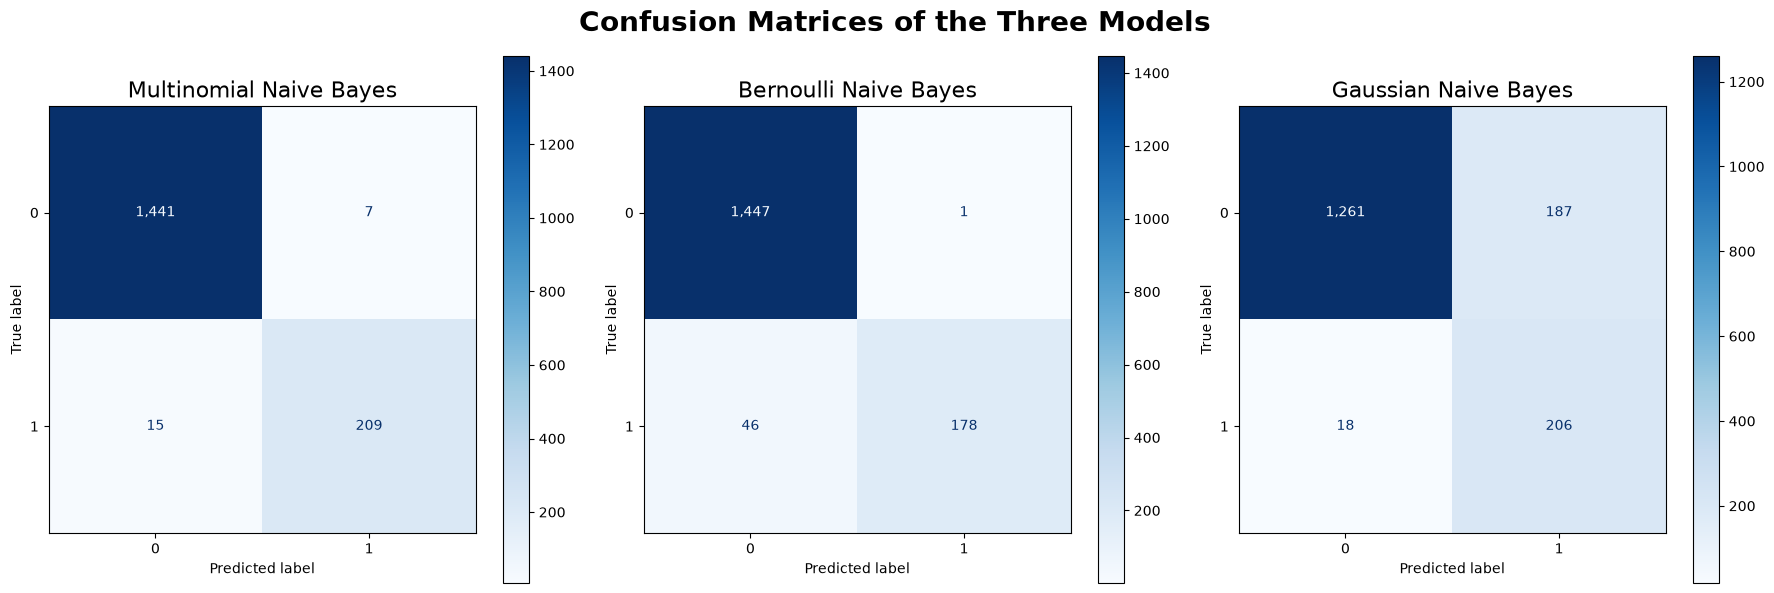

In [9]:
# setting up the plot size for side-by-side display
fig, axes = plt.subplots(
    nrows = 1,
    ncols = 3,
    figsize = (18, 6)
)
fig.suptitle(
    t = "Confusion Matrices of the Three Models",
    fontsize = 20,
    fontweight = "bold"
)

# MultinomialNB
matrix_mnb = confusion_matrix(y_true = y_test, y_pred = y_predict_test_mnb)
ConfusionMatrixDisplay(confusion_matrix = matrix_mnb).plot(
    ax = axes[0],
    cmap = "Blues",
    values_format = ",.0f"
)
axes[0].set_title(label = "Multinomial Naive Bayes", fontsize = 16)

# BernoulliNB
matrix_bnb = confusion_matrix(y_true = y_test, y_pred = y_predict_test_bnb)
ConfusionMatrixDisplay(confusion_matrix = matrix_bnb).plot(
    ax = axes[1],
    cmap = "Blues",
    values_format = ",.0f"
)
axes[1].set_title(label = "Bernoulli Naive Bayes", fontsize = 16)

# GaussianNB
matrix_gnb = confusion_matrix(y_true = y_test, y_pred = y_predict_test_gnb)
ConfusionMatrixDisplay(confusion_matrix = matrix_gnb).plot(
    ax = axes[2],
    cmap = "Blues",
    values_format = ",.0f"
)
axes[2].set_title(label = "Gaussian Naive Bayes", fontsize = 16)

# displaying the subplots
plt.tight_layout()
plt.show()

<div style="text-align: justify;">

**Key Insights:**

Now, our goals are to either have the minimum number false positive or false negative predictions. Depending on the context and what we want to achieve, we can choose to prioritize one over the other.

* If our objective is to minimize false positives, i.e., we want to avoid incorrectly identifying a ham message as spam, then the best model would be the one with the lowest false positive rate. In this case, that model here is the **Bernoulli Naive Bayes** model (only 1 out of 1448). We must choose this model if we absolutely cannot afford to lose important emails (like business communications, bank notifications, etc.).

* On the other hand, if our objective is to minimize false negatives, i.e., we want to avoid incorrectly identifying a spam message as ham, then the best model would be the one with the lowest false negative rate. In this case, that model here is the **Multinomial Naive Bayes** model (only 15 out of 224). We will choose this model if security and avoiding malicious content is our priority.

* If we are looking for a balance between the false positive and false negative on the other hand, **Multinomial Bayes Model** is the best among the three. It catches almost the majority of the spam messages (209 messages in true positive) whilst having the least number of false negative messages and second least number of false positive messages.

</div>

### **Receiver Operating Characteristic (**ROC**) Curves & Area Under Curve (**AUC**) Scores**

Generating the False Positive Rate (FPR), True Positive Rate (TPR), and thresholds for all three models to plot the ROC Curves. In this cell, we only calculate these values. In the next couple of cells, we will calculate the ROC-AUC scores and plot them with the ROC curves in the same graph.

In [10]:
# MultinomialNB
y_prob_mnb = mnb_pipeline.predict_proba(X = X_test)[:, 1]
fpr_mnb, tpr_mnb, thresholds_mnb = roc_curve(y_true = y_test, y_score = y_prob_mnb)

# BernoulliNB
y_prob_bnb = bnb_pipeline.predict_proba(X = X_test)[:, 1]
fpr_bnb, tpr_bnb, thresholds_bnb = roc_curve(y_true = y_test, y_score = y_prob_bnb)

# GaussianNB
y_prob_gnb = gnb_pipeline.predict_proba(X = X_test)[:, 1]
fpr_gnb, tpr_gnb, thresholds_gnb = roc_curve(y_true = y_test, y_score = y_prob_gnb)

Now, we calculate the ROC-AUC for all the three models and take a look at their values.

In [11]:
# calculating the ROC-AUC for the three models
roc_score_mnb = roc_auc_score(y_true = y_test, y_score = y_prob_mnb)
roc_score_bnb = roc_auc_score(y_true = y_test, y_score = y_prob_bnb)
roc_score_gnb = roc_auc_score(y_true = y_test, y_score = y_prob_gnb)

# printing the results
print(
f"""ROC-AUC Scores of the Three Models
      
Multinomial Naive Bayes: {roc_score_mnb:.3%}
Bernoulli Naive Bayes: {roc_score_bnb:.3%}
Gaussian Naive Bayes: {roc_score_gnb:.3%}"""
)

ROC-AUC Scores of the Three Models

Multinomial Naive Bayes: 99.066%
Bernoulli Naive Bayes: 99.128%
Gaussian Naive Bayes: 89.525%


Now, we plot the ROC curves of all the three models along with their ROC-AUC scores in the same graph for a better comparison. We colour-coded the curves and formatted the graph accordingly for easier comparison.

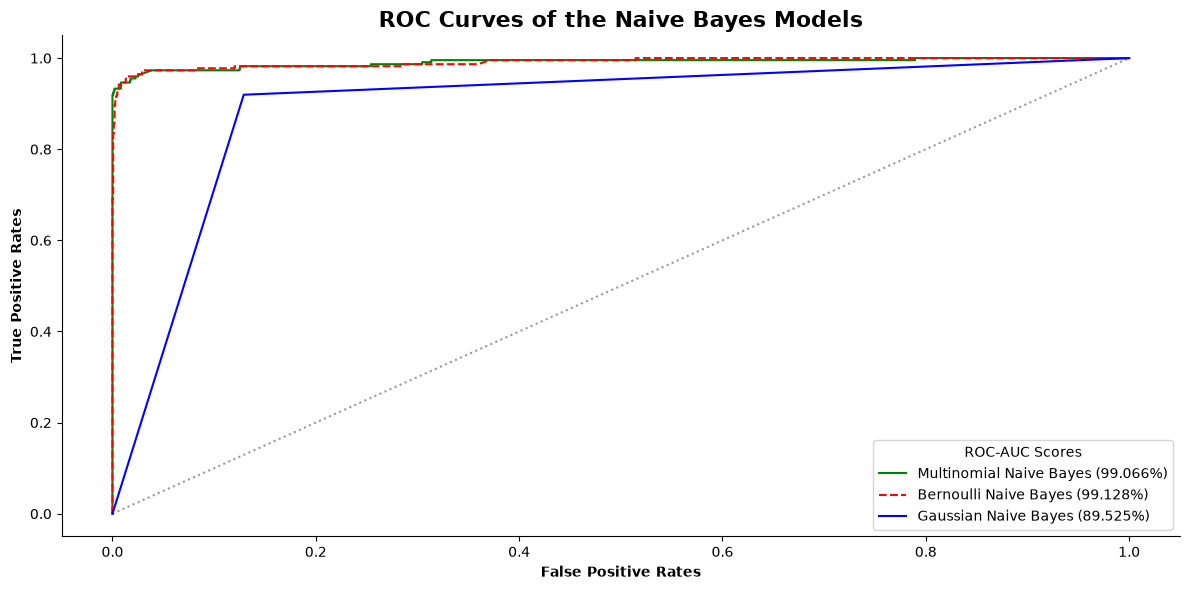

In [12]:
# fixing the plot size
plt.figure(figsize = (12,6))

# plotting a 45-degree reference line
plt.plot([0, 1], [0, 1], color = "black", linestyle = "dotted", alpha = 0.4)

# plotting the ROC curves
plt.plot(
    fpr_mnb,
    tpr_mnb,
    label = f"Multinomial Naive Bayes ({roc_score_mnb:.3%})",
    color = "green"
)
plt.plot(
    fpr_bnb,
    tpr_bnb,
    label = f"Bernoulli Naive Bayes ({roc_score_bnb:.3%})",
    color = "red",
    linestyle = "--"
)
plt.plot(
    fpr_gnb,
    tpr_gnb,
    label = f"Gaussian Naive Bayes ({roc_score_gnb:.3%})",
    color = "blue"
)

# formatting the plot
plt.title(label = "ROC Curves of the Naive Bayes Models", fontsize = 16, fontweight = "bold")
plt.xlabel(xlabel = "False Positive Rates", fontweight = "bold")
plt.ylabel(ylabel = "True Positive Rates", fontweight = "bold")
plt.legend(title = "ROC-AUC Scores", loc = 4)
sns.despine()
plt.tight_layout()
plt.show()

<div style="text-align: justify;">

**Key Insights:**

* The ROC curves show that **Multinomial Naive Bayes** and **Bernoulli Naive Bayes** both achieved excellent discrimination ability between spam and ham messages, with AUC scores of 99.066% and 99.128% respectively. They can be considered almost equal if we account for the decimal places. Their ROC curves nearly touch the top-left corner, indicating near-perfect classification performance.

* In contrast, **Gaussian Naive Bayes** performed notably worse, with an AUC of 89.53%, showing that it is less effective at distinguishing between the two classes.

</div>

### **Overfitting Check**

<div style="text-align: justify;">

Before finally selecting on a model, we want to check whether any of the models have any overfitting issues. ***Overfitting** is a common problem in machine learning where a model learns the training data too well, including its noise and specific patterns, making it perform poorly on new, unseen data*. 

Usually one of the telltale signs of overfitting is a large difference between the training and testing f1 scores of a model. If a model has a very high training f1 score but a significantly lower testing f1 score, it may be overfitting the training data. We have already determined the f1 scores of the test data of the models, now we start by calculating the training f1 scores of all three models.

</div>

In [13]:
# determining the y_predict values of the train datasets for the models
y_predict_train_mnb = mnb_pipeline.predict(X = X_train)
y_predict_train_bnb = bnb_pipeline.predict(X = X_train)
y_predict_train_gnb = gnb_pipeline.predict(X = X_train)

# calculating the F1 scores (spam class) of the train dataset for the three models
f1_train_mnb = f1_score(y_true = y_train, y_pred = y_predict_train_mnb)
f1_train_bnb = f1_score(y_true = y_train, y_pred = y_predict_train_bnb)
f1_train_gnb = f1_score(y_true = y_train, y_pred = y_predict_train_gnb)

# printing the F1 scores of both the train and test datasets and checking the difference
print(
f"""Train & Test F1 Scores (Spam) & their Differences

For Multinomial Naive Bayes
Train F1: {f1_train_mnb:.2%}
Test F1: {f1_test_mnb:.2%}
Difference in F1: {f1_train_mnb - f1_test_mnb:.2%}

For Bernoulli Naive Bayes
Train F1: {f1_train_bnb:.2%}
Test F1: {f1_test_bnb:.2%}
Difference in F1: {f1_train_bnb - f1_test_bnb:.2%}

For Gaussian Naive Bayes
Train F1: {f1_train_gnb:.2%}
Test F1: {f1_test_gnb:.2%}
Difference in F1: {f1_train_gnb - f1_test_gnb:.2%}"""
)

Train & Test F1 Scores (Spam) & their Differences

For Multinomial Naive Bayes
Train F1: 97.62%
Test F1: 95.00%
Difference in F1: 2.62%

For Bernoulli Naive Bayes
Train F1: 94.16%
Test F1: 88.34%
Difference in F1: 5.83%

For Gaussian Naive Bayes
Train F1: 81.15%
Test F1: 66.77%
Difference in F1: 14.37%


<div style="text-align: justify;">

**Key Insights:**

* The train–test f1 score comparison shows that **Multinomial Naive Bayes** generalizes the best, with nearly identical training (97.62%) and testing (95.00%) f1 scores and the smallest gap (2.62%), indicating minimal overfitting.

* **Bernoulli Naive Bayes** also performs well, though its slightly larger gap (5.83%) suggests a bit higher variance but still stable performance.

* In contrast, **Gaussian Naive Bayes** displays a significant gap (14.37%), meaning it performs much better on training data than on unseen data, a sign of overfitting.

So, from the above data we can see that, MultinomialNB shows the best generalization and is the most reliable model for spam detection, while GaussianNB struggles due to its mismatch with text data.

</div>

### **Cross-Validation Check**

<div style="text-align: justify;">

Now, we want to have another check on how our models perform on new and unseen data. Another method of testing this is through cross-validation. ***Cross-validation** is a statistical technique used to evaluate machine learning models by splitting the data into multiple subsets and training/testing the model multiple times to get a more robust estimate of its performance*.

Instead of doing just one train–test split, cross-validation splits the data multiple times in different ways and checks model performance across all splits. This gives us a more reliable estimate of how well the model will perform in the real world.

For this dataset, we perform a **k-Fold Cross Validation**, one of the most common cross-validation methods. In k-Fold Cross Validation, the dataset is divided into `k` equal parts or folds. The model is trained on `k-1` folds and tested on the remaining fold. This process is repeated `k` times, with each fold being used as the test set once. The final performance metric is then averaged over all `k` iterations to provide a more robust estimate of the model's performance. For our dataset, we use a **5**-Fold Cross Validation (for classifiers, `cross_val_score` automatically keeps the ham:spam ratio the same in every fold).

We pass the raw training text (`X_train`) and the pipelines we defined earlier. `cross_val_score()` clones each pipeline for every fold, so the vectorizer is refit on that fold's training part only, as explained in the pipelines section. Accuracy can look great on an imbalanced dataset even if a model is weak at catching spam, because predicting "ham" for everything already gets about 87%. So we score the models on the spam-class **F1 score**, which is the most important metric for this imbalanced dataset. We will check the cross-validation results in the next cell.



</div>

Cross Validation F1 Scores of the Three Models

Multinomial Naive Bayes: 93.79% ± 2.50%
Bernoulli Naive Bayes: 85.78% ± 1.65%
Gaussian Naive Bayes: 64.16% ± 2.62%


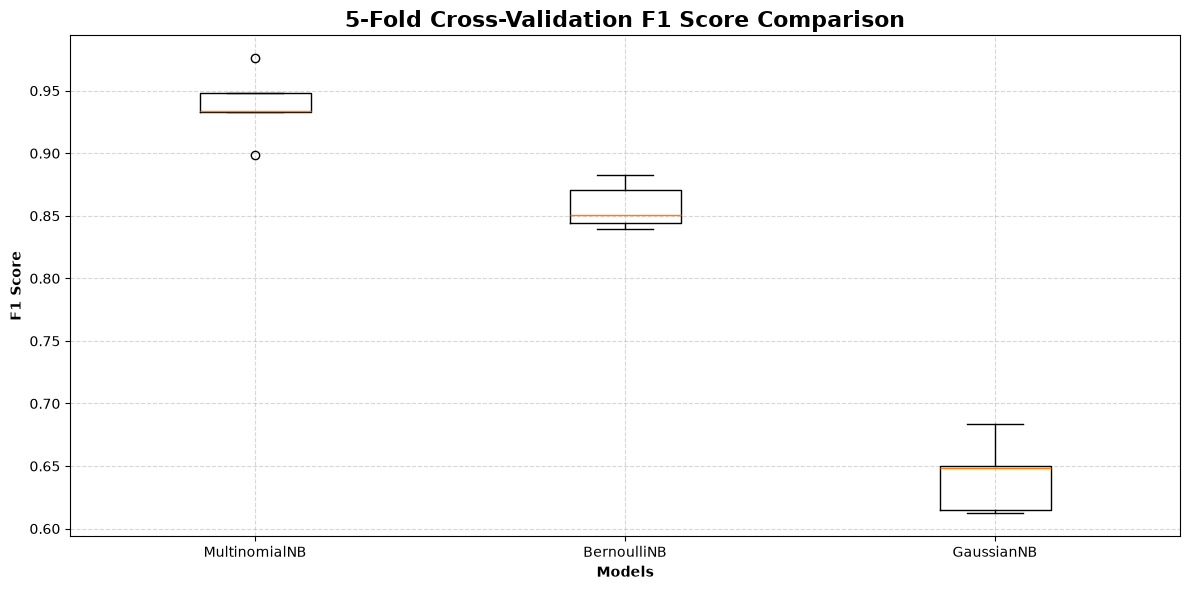

In [14]:
# calculating the 5-fold cross validation F1 scores using the raw text (X_train)
# MultinomialNB
cv_f1_mnb = cross_val_score(
    estimator = mnb_pipeline,
    X = X_train,
    y = y_train,
    cv = 5,
    scoring = "f1"
)

# BernoulliNB
cv_f1_bnb = cross_val_score(
    estimator = bnb_pipeline,
    X = X_train,
    y = y_train,
    cv = 5,
    scoring = "f1"
)

# GaussianNB
cv_f1_gnb = cross_val_score(
    estimator = gnb_pipeline,
    X = X_train,
    y = y_train,
    cv = 5,
    scoring = "f1"
)

# printing the results
print(
f"""Cross Validation F1 Scores of the Three Models

Multinomial Naive Bayes: {np.mean(cv_f1_mnb):.2%} ± {np.std(cv_f1_mnb):.2%}
Bernoulli Naive Bayes: {np.mean(cv_f1_bnb):.2%} ± {np.std(cv_f1_bnb):.2%}
Gaussian Naive Bayes: {np.mean(cv_f1_gnb):.2%} ± {np.std(cv_f1_gnb):.2%}"""
)

# visualizing the results for a better overview
plt.figure(figsize = (12, 6))
plt.boxplot(x = [cv_f1_mnb, cv_f1_bnb, cv_f1_gnb])
plt.xticks(ticks = [1, 2, 3], labels = ["MultinomialNB", "BernoulliNB", "GaussianNB"])
plt.xlabel(xlabel = "Models", fontweight = "bold")
plt.title(label = "5-Fold Cross-Validation F1 Score Comparison", fontsize = 16, fontweight = "bold")
plt.ylabel(ylabel = "F1 Score", fontweight = "bold")
plt.grid(visible = True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

<div style="text-align: justify;">

**Key Insights:**

Among the three models, **Multinomial Naive Bayes** achieved the highest cross-validation F1 score (93.79% ± 2.50%), followed by **Bernoulli Naive Bayes** (85.78% ± 1.65%), while **Gaussian Naive Bayes** performed considerably worse (64.16% ± 2.62%).

MultinomialNB demonstrated the strongest overall performance in balancing precision and recall, making it the most effective model for identifying spam messages. BernoulliNB showed greater consistency across folds, as indicated by its lower standard deviation, although its F1 score was substantially lower. GaussianNB performed worst, likely because its assumption of normally distributed features is poorly suited to text-based TF-IDF features. These results suggest that MultinomialNB is the most promising model for this imbalanced dataset, where accuracy alone could obscure poor spam detection.

To examine how the models' F1 scores varied across individual folds, we can visualize the results using a heatmap.

</div>

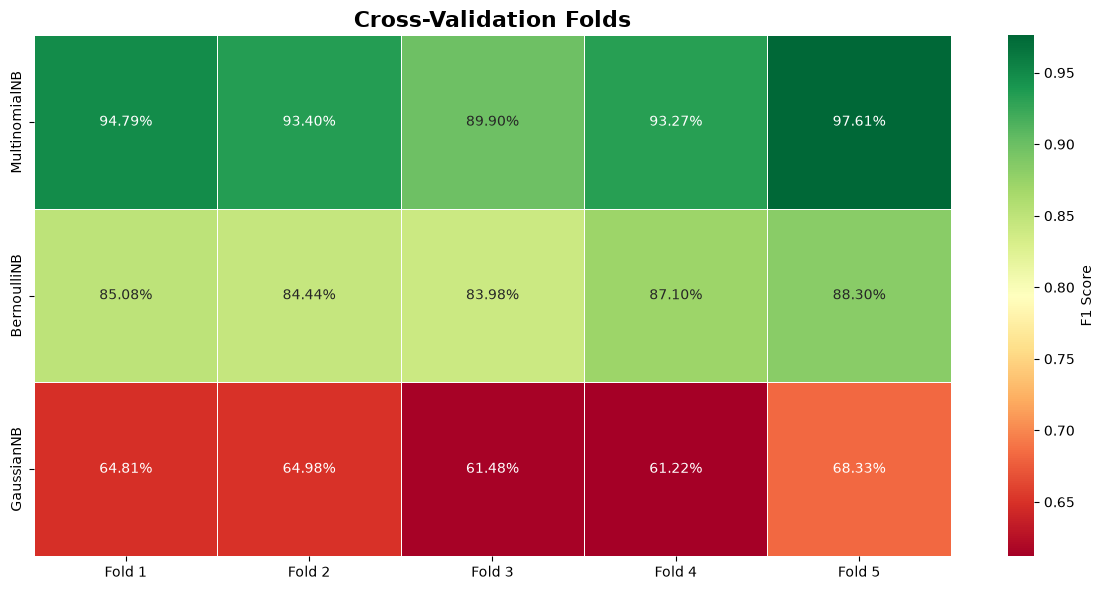

F1 Score range across the folds
MultinomialNB: 89.90% to 97.61%
BernoulliNB: 83.98% to 88.30%
GaussianNB: 61.22% to 68.33%

Best model in each fold:
Fold 1    MultinomialNB
Fold 2    MultinomialNB
Fold 3    MultinomialNB
Fold 4    MultinomialNB
Fold 5    MultinomialNB


In [ ]:
# creating a DataFrame for the heatmap (one row per model, one column per fold)
heatmap_df = pd.DataFrame(
    data = [cv_f1_mnb, cv_f1_bnb, cv_f1_gnb],
    index = ["MultinomialNB", "BernoulliNB", "GaussianNB"],
    columns = [f"Fold {fold}" for fold in range(1, len(cv_f1_mnb) + 1)]
)

# setting up the plot
plt.figure(figsize = (12, 6))

# creating the heatmap
sns.heatmap(
    data = heatmap_df,
    annot = True,
    fmt = ".2%",
    cmap = "RdYlGn",
    cbar_kws = {"label": "F1 Score"},
    linewidths = 0.5,
    linecolor = "white"
)

# formatting the plot
plt.title(label = "Cross-Validation Folds", fontsize = 16, fontweight = "bold")
plt.tight_layout()
plt.show()

# printing the lowest and highest F1-scores across folds
print("F1 Score range across the folds")
for model_name, fold_scores in heatmap_df.iterrows():
    print(f"{model_name}: {fold_scores.min():.2%} to {fold_scores.max():.2%}")

# checking which model is the best in each fold
print(f"\nBest model in each fold:\n{heatmap_df.idxmax(axis = 0).to_string()}")

<div style="text-align: justify;">

**Key Insights:**

The fold-level results show whether the models' relative performance remains consistent across the five validation folds. **MultinomialNB** achieved the highest F1-score in every fold, reinforcing its position as the strongest performer in this comparison. **BernoulliNB** had a lower mean F1-score but less variation across folds, while **GaussianNB** consistently performed worst. These results support selecting MultinomialNB for further consideration, although the final assessment should also account for the held-out test results and the practical costs of false positives and false negatives.

</div>

## Model Comparison across Three Metrics

<div style="text-align: justify;">

Finally, we want to compare the performance of the three models across **three** specific metrics: Accuracy, F1 Score, and ROC-AUC Score. We will create a bar plot for each metric to visually compare the models.

To do that, we first create a dataframe that contains the metrics for each model called `metric_data`. Then, we use the `melt` function from pandas to transform the dataframe into a long format suitable for seaborn's `barplot` function. Finally, we plot the bar plots for each metric using seaborn's `barplot` function and format the graphs accordingly.

</div>

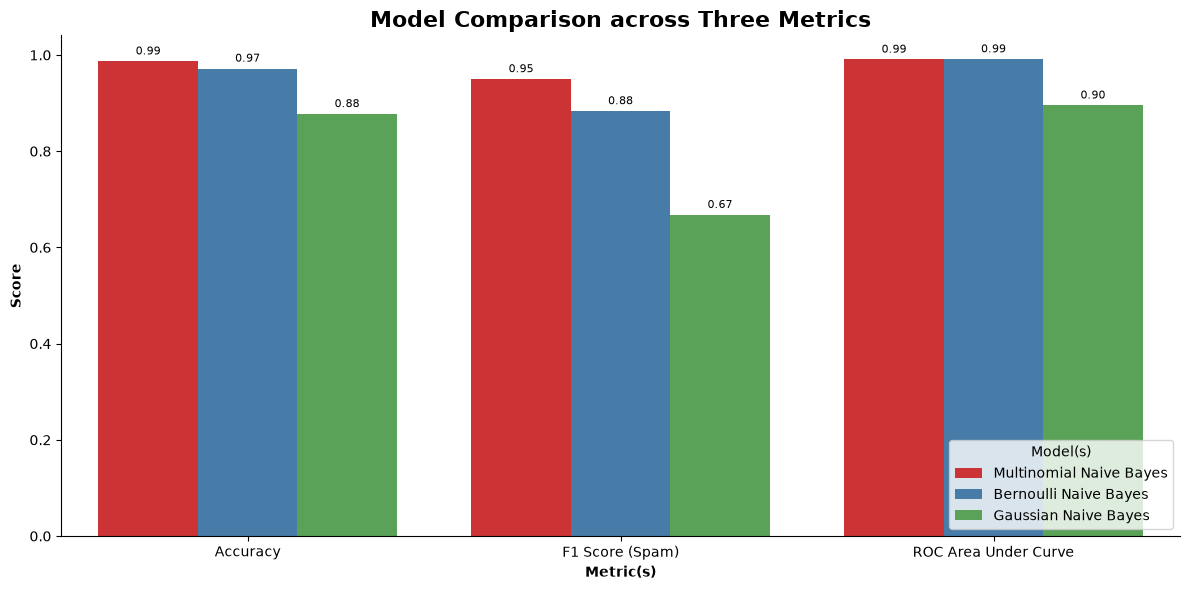

In [16]:
# creating a short dataset for the visualization
metric_data = pd.DataFrame(
    {
        "Model": ["Multinomial Naive Bayes", "Bernoulli Naive Bayes", "Gaussian Naive Bayes"],
        "Accuracy": [accuracy_test_mnb, accuracy_test_bnb, accuracy_test_gnb],
        "F1 Score (Spam)": [f1_test_mnb, f1_test_bnb, f1_test_gnb],
        "ROC Area Under Curve": [roc_score_mnb, roc_score_bnb, roc_score_gnb]
    }
)

# melting the dataset to long format for seaborn visualization
metric_data_melted = metric_data.melt(
    id_vars = "Model",
    value_vars = ["Accuracy", "F1 Score (Spam)", "ROC Area Under Curve"],
    var_name = "Metric",
    value_name = "Score"
)

# plotting side-by-side bar chart
plt.figure(figsize = (12, 6))
ax = sns.barplot(
    data = metric_data_melted,
    x = "Metric",
    y = "Score",
    hue = "Model",
    palette = "Set1"
)

# adding labels on top of each bar for easier understanding
for container in ax.containers:
    ax.bar_label(
        container = container,
        fmt = "%.2f",
        label_type = "edge",
        fontsize = 8,
        padding = 3
    )

# formatting the plot
plt.title(label = "Model Comparison across Three Metrics", fontsize = 16, fontweight = "bold")
plt.xlabel(xlabel = "Metric(s)", fontweight = "bold")
plt.ylabel(ylabel = "Score", fontweight = "bold")
plt.legend(title = "Model(s)", loc = 4)
sns.despine()
plt.tight_layout()
plt.show()

<div style="text-align: justify;">

**Key Insights:**

As shown in the chart, Multinomial Naive Bayes achieved the highest test accuracy and spam-class F1-score, while Bernoulli Naive Bayes achieved a marginally higher ROC-AUC. GaussianNB performed worst across all three metrics.

Given the importance of balancing precision and recall when detecting spam in this imbalanced dataset, **Multinomial Naive Bayes** is the strongest overall candidate among the three models.

</div>

# **Conclusion**

<div style="text-align: justify;">

Based on the evaluation results, Multinomial Naive Bayes emerged as the strongest overall model for this SMS spam classification task. It achieved 98.68% test accuracy and a 95.00% spam-class F1-score, while also recording the highest mean cross-validation F1-score (93.79% ± 2.50%). Its strong performance with word-count features makes it a suitable candidate for this text classification problem.

It makes the perfect sense since it accounts for how many times one word appears in a text. Gaussian Naive Bayes performed poorly because this dataset was a text-based one and GNB performs the best in numeric features. Although the dataset was encoded using TF-IDF, this model was not the best one for this dataset.

**Methodological note:** Every evaluation in this notebook goes through the same three scikit-learn `Pipeline` objects, which bundle the text vectorizer and the classifier. For the test-set evaluation (accuracy, confusion matrices, ROC curves, overfitting check), each pipeline is fitted on the training set only and then applied to the untouched test set. For the cross-validation, `cross_val_score` refits the whole pipeline, vectorizer included, on the training part of each fold, which avoids the preprocessing leakage that occurs when a vectorizer is fitted on the entire training set before the folds are created.


**Performance of MNB**:

| ***Metric*** | **Accuracy** | **Precision** | **Recall** | **F1 score** | **False Positive Rate** | **False Negative Rate** | **ROC-AUC** |
|------------|--------------|---------------|------------|--------------|-------------------------|-------------------------|-------------|
| ***Value***  | 98.68%       | 97%           | 93%        | 95%          | 0.48%                   | 6.70%                   | 99.07%      |

<u>So, to rank the performance of the **three** models</u>:
1. Multinomial Naive Bayes
2. Bernoulli Naive Bayes
3. Gaussian Naive Bayes

</div>